In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import root_mean_squared_error
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import statsmodels.api as sm
from statsmodels.tsa.arima.model import ARIMA


import warnings 
warnings.filterwarnings('ignore')

In [18]:
df = pd.read_csv(r"C:\Users\PGCP-AI.STUDENTSDC\Desktop\Machine_Learning\Datasets\FMAC-HPI_24420.csv")
df.head()

,Date,NSA Value,SA Value
0,31-01-1975,24.739893,24.687815
1,28-02-1975,25.266825,25.200482
2,31-03-1975,25.765667,25.633002
3,30-04-1975,26.212724,26.009987
4,31-05-1975,26.628081,26.350592


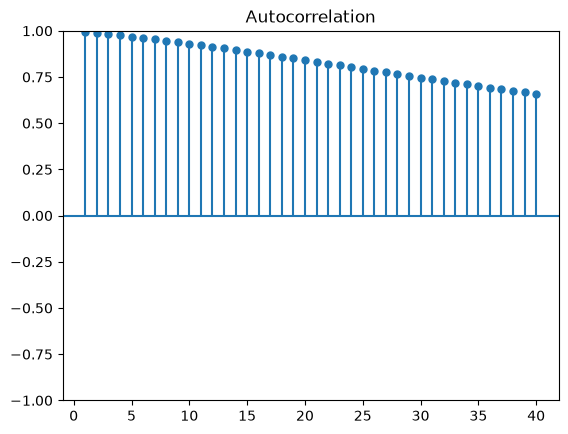

In [19]:
plot_acf(df['NSA Value'], lags=40, alpha=None, zero=False)
plt.show()

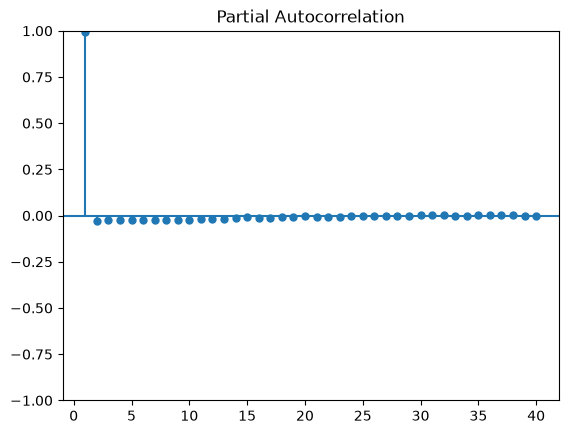

In [20]:
plot_pacf(df['NSA Value'], lags=40, alpha=None, zero=False)
plt.show()

In [21]:
y = df['NSA Value']
y_train = y[:-12]
y_test = y[-12:]

In [22]:
# ARIMA(p, d, q) -> order=(ar_order, differencing, ma_order)
model = ARIMA(y_train, order=(2,1,1))
model_fit = model.fit()
print('Coefficients : %s'% model_fit.params)

Coefficients : ar.L1     1.473144
ar.L2    -0.589775
ma.L1     0.999739
sigma2    0.035254
dtype: float64


In [23]:
predictions = model_fit.predict(start=len(y_train), end=len(y_train)+len(y_test)-1)
error = root_mean_squared_error(y_test, predictions)
print('Test RMSE : %.3f'%error)

Test RMSE : 3.184


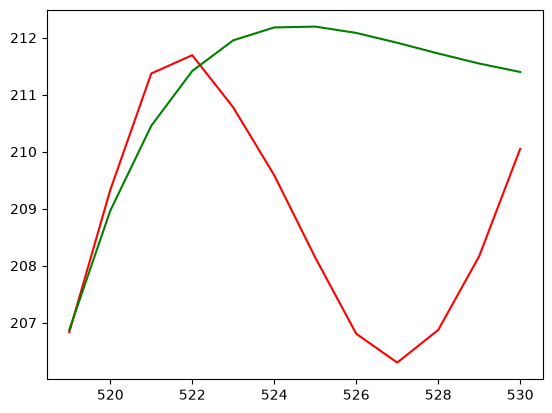

In [24]:
y_test.plot(color='r')
predictions.plot(color='g')
plt.show()

## Auto-ARIMA

In [25]:
from pmdarima.arima import auto_arima

In [26]:
model = auto_arima(y_train, trace=True, error_action='ignore', surpress_warnings=True)

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=-258.744, Time=0.78 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=1625.721, Time=0.02 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=545.901, Time=0.16 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=inf, Time=0.36 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=1668.139, Time=0.02 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=-211.845, Time=0.55 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=inf, Time=0.76 sec
 ARIMA(3,1,2)(0,0,0)[0] intercept   : AIC=inf, Time=1.23 sec
 ARIMA(2,1,3)(0,0,0)[0] intercept   : AIC=inf, Time=2.13 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=inf, Time=0.66 sec
 ARIMA(1,1,3)(0,0,0)[0] intercept   : AIC=inf, Time=1.38 sec
 ARIMA(3,1,1)(0,0,0)[0] intercept   : AIC=inf, Time=0.51 sec
 ARIMA(3,1,3)(0,0,0)[0] intercept   : AIC=inf, Time=2.28 sec
 ARIMA(2,1,2)(0,0,0)[0]             : AIC=-254.857, Time=0.64 sec

Best model:  ARIMA(2,1,2)(0,0,0)[0] intercept
Total fit time: 11.497 seco

In [27]:
model.bse

<bound method ARIMA.bse of ARIMA(order=(2, 1, 2), scoring_args={}, suppress_warnings=True)>

In [28]:
forecast = model.predict(n_periods=len(y_test))
forecast = pd.DataFrame(forecast, index=y_test.index, columns=['Prediction'])
forecast

,Prediction
519,206.757714
520,208.642648
521,209.989679
522,210.947673
523,211.640478
524,212.162932
525,212.583081
526,212.946950
527,213.283866
528,213.611265


In [29]:
error = root_mean_squared_error(y_test, forecast)
print('Test RMSE : %.3f'%error)

Test RMSE : 4.213


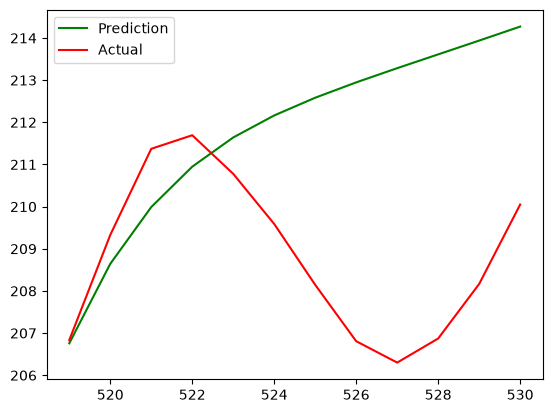

In [30]:
forecast.plot(color='g', label='Prediction')
y_test.plot(color='r', label='Actual')
plt.legend()
plt.show()

# Exercise

In [31]:
df = pd.read_csv(r"C:\Users\PGCP-AI.STUDENTSDC\Desktop\Machine_Learning\Datasets\monthly-milk-production-pounds-p.csv")
df.head()

,Month,Milk
0,1962-01,589
1,1962-02,561
2,1962-03,640
3,1962-04,656
4,1962-05,727


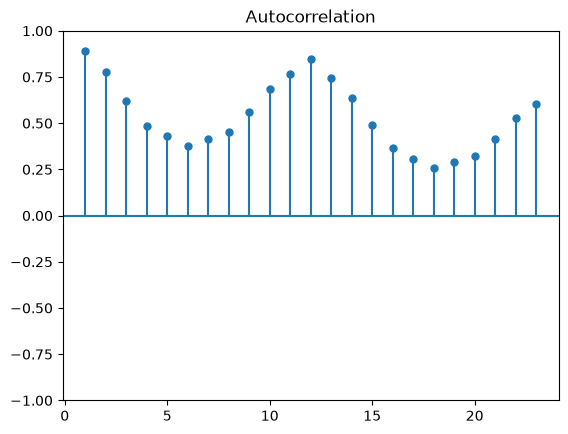

In [32]:
plot_acf(df['Milk'],alpha=None, zero=False)
plt.show()

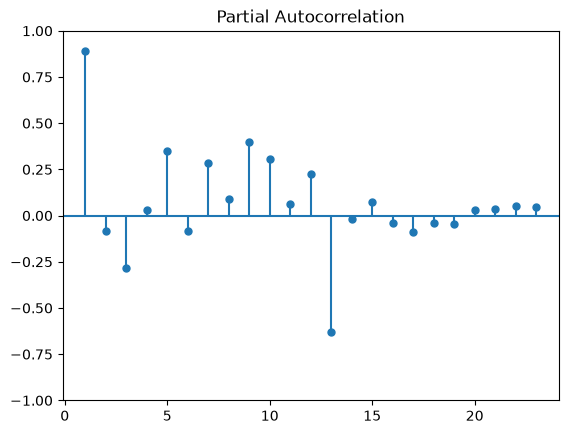

In [33]:
plot_pacf(df['Milk'],alpha=None, zero=False)
plt.show()

In [34]:
y = df['Milk']
y_train = y[:-12]
y_test = y[-12:]

In [35]:
model = auto_arima(y_train, trace=True, error_action='ignore', surpress_warnings=True)

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=1593.685, Time=0.60 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=1624.299, Time=0.01 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=1626.095, Time=0.06 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=1626.164, Time=0.11 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=1622.458, Time=0.01 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=1604.395, Time=0.29 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=1618.644, Time=0.24 sec
 ARIMA(3,1,2)(0,0,0)[0] intercept   : AIC=inf, Time=0.60 sec
 ARIMA(2,1,3)(0,0,0)[0] intercept   : AIC=1572.322, Time=0.89 sec
 ARIMA(1,1,3)(0,0,0)[0] intercept   : AIC=inf, Time=0.62 sec
 ARIMA(3,1,3)(0,0,0)[0] intercept   : AIC=inf, Time=1.01 sec
 ARIMA(2,1,4)(0,0,0)[0] intercept   : AIC=inf, Time=1.28 sec
 ARIMA(1,1,4)(0,0,0)[0] intercept   : AIC=1561.833, Time=1.31 sec
 ARIMA(0,1,4)(0,0,0)[0] intercept   : AIC=inf, Time=1.18 sec
 ARIMA(1,1,5)(0,0,0)[0] intercept   : AIC=inf, Time=1.26 s

In [36]:
model.bse

<bound method ARIMA.bse of ARIMA(order=(1, 1, 4), scoring_args={}, suppress_warnings=True)>

In [37]:
forecast = model.predict(n_periods=len(y_test))
forecast = pd.DataFrame(forecast, index=y_test.index, columns=['Prediction'])
forecast

,Prediction
156,834.406855
157,856.268000
158,886.335498
159,886.611703
160,888.849848
161,890.426900
162,892.226714
163,893.951466
164,895.701510
165,897.443032


In [38]:
error = root_mean_squared_error(y_test, forecast)
print('Test RMSE : %.3f'%error)

Test RMSE : 57.878


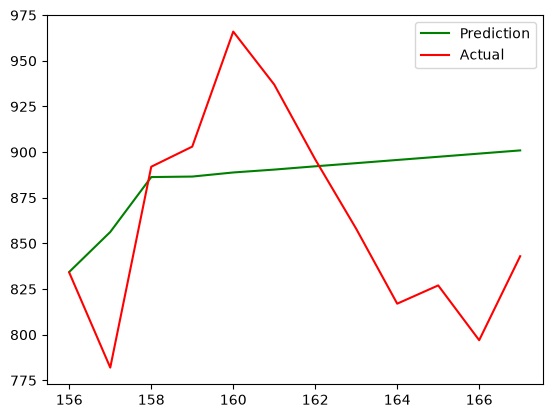

In [39]:
forecast.plot(color='g', label='Prediction')
y_test.plot(color='r', label='Actual')
plt.legend()
plt.show()

# SARIMA

In [40]:
s_model = auto_arima(y_train, trace=True, error_action='ignore', surpress_warnings=True, seasonal=True, m=12) 

Performing stepwise search to minimize aic
 ARIMA(2,0,2)(1,1,1)[12] intercept   : AIC=1000.136, Time=2.56 sec
 ARIMA(0,0,0)(0,1,0)[12] intercept   : AIC=1218.095, Time=0.04 sec
 ARIMA(1,0,0)(1,1,0)[12] intercept   : AIC=1015.855, Time=0.60 sec
 ARIMA(0,0,1)(0,1,1)[12] intercept   : AIC=1104.312, Time=0.41 sec
 ARIMA(0,0,0)(0,1,0)[12]             : AIC=1349.320, Time=0.03 sec
 ARIMA(2,0,2)(0,1,1)[12] intercept   : AIC=998.169, Time=1.68 sec
 ARIMA(2,0,2)(0,1,0)[12] intercept   : AIC=1038.230, Time=0.47 sec
 ARIMA(2,0,2)(0,1,2)[12] intercept   : AIC=1000.125, Time=3.25 sec
 ARIMA(2,0,2)(1,1,0)[12] intercept   : AIC=1012.395, Time=1.48 sec
 ARIMA(2,0,2)(1,1,2)[12] intercept   : AIC=inf, Time=5.77 sec
 ARIMA(1,0,2)(0,1,1)[12] intercept   : AIC=996.457, Time=0.81 sec
 ARIMA(1,0,2)(0,1,0)[12] intercept   : AIC=1036.989, Time=0.25 sec
 ARIMA(1,0,2)(1,1,1)[12] intercept   : AIC=998.423, Time=1.50 sec
 ARIMA(1,0,2)(0,1,2)[12] intercept   : AIC=998.411, Time=2.00 sec
 ARIMA(1,0,2)(1,1,0)[12] int

In [41]:
s_model.bse

<bound method ARIMA.bse of ARIMA(order=(3, 0, 1), scoring_args={}, seasonal_order=(0, 1, 1, 12),
      suppress_warnings=True)>

In [42]:
forecast = s_model.predict(n_periods=len(y_test))
prediction = pd.DataFrame(forecast, index=y_test.index, columns=['Prediction'])
prediction

,Prediction
156,838.789468
157,797.309925
158,902.001375
159,918.983705
160,982.162606
161,957.974296
162,916.613064
163,877.743339
164,828.806807
165,832.278878


In [43]:
rms = root_mean_squared_error(y_test, prediction)
print('Total RMSE : %.3f' %rms)

Total RMSE : 13.941


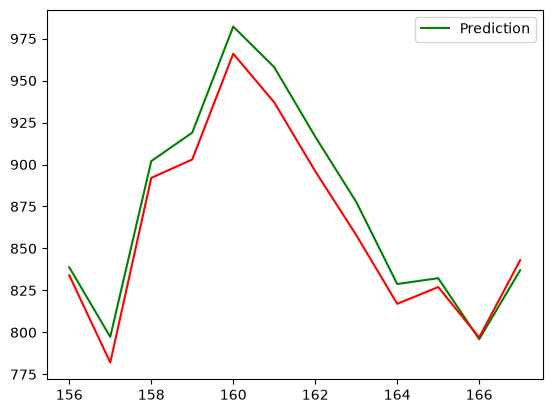

In [44]:
prediction.plot(color='g')
y_test.plot(color='r')
plt.show()

# Exercise

In [45]:
df = pd.read_csv(r"C:\Users\PGCP-AI.STUDENTSDC\Desktop\Machine_Learning\Datasets\AusGas.csv")
df.head()

,Month,GasProd
0,Jan-1956,1709
1,Feb-1956,1646
2,Mar-1956,1794
3,Apr-1956,1878
4,May-1956,2173


In [46]:
df.shape

(476, 2)

In [47]:
y = df['GasProd']
y_train = y[:-12]
y_test = y[-12:]

[]

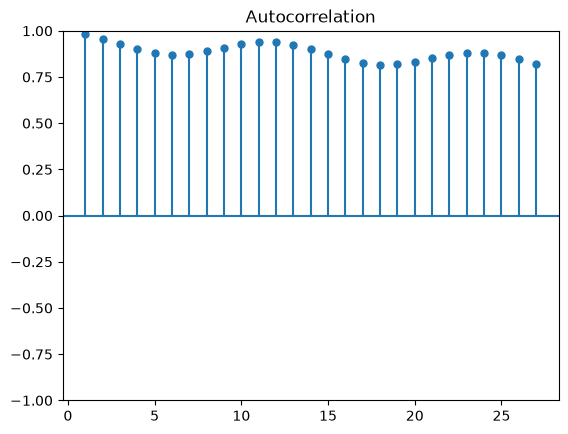

In [48]:
plot_acf(y, alpha=None, zero=False)
plt.plot()

[]

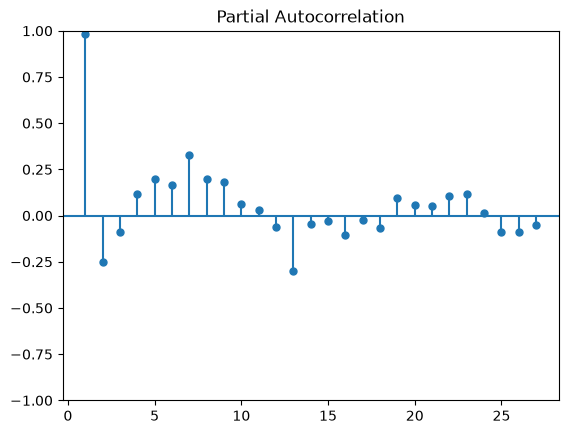

In [49]:
plot_pacf(y, alpha=None, zero=False)
plt.plot()

In [50]:
model = auto_arima(y_train, trace=True, error_action='ignore', surpress_warnings=True, seasonal=True, m=12)

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(1,0,1)[12] intercept   : AIC=inf, Time=3.80 sec
 ARIMA(0,1,0)(0,0,0)[12] intercept   : AIC=8632.352, Time=0.04 sec
 ARIMA(1,1,0)(1,0,0)[12] intercept   : AIC=8255.565, Time=1.33 sec
 ARIMA(0,1,1)(0,0,1)[12] intercept   : AIC=8438.509, Time=0.97 sec
 ARIMA(0,1,0)(0,0,0)[12]             : AIC=8631.502, Time=0.01 sec
 ARIMA(1,1,0)(0,0,0)[12] intercept   : AIC=8589.946, Time=0.04 sec
 ARIMA(1,1,0)(2,0,0)[12] intercept   : AIC=inf, Time=2.78 sec
 ARIMA(1,1,0)(1,0,1)[12] intercept   : AIC=8170.931, Time=2.16 sec
 ARIMA(1,1,0)(0,0,1)[12] intercept   : AIC=8438.053, Time=0.71 sec
 ARIMA(1,1,0)(2,0,1)[12] intercept   : AIC=8218.685, Time=4.70 sec
 ARIMA(1,1,0)(1,0,2)[12] intercept   : AIC=8204.884, Time=5.76 sec
 ARIMA(1,1,0)(0,0,2)[12] intercept   : AIC=8371.138, Time=2.35 sec
 ARIMA(1,1,0)(2,0,2)[12] intercept   : AIC=inf, Time=5.85 sec
 ARIMA(0,1,0)(1,0,1)[12] intercept   : AIC=8219.426, Time=1.84 sec
 ARIMA(2,1,0)(1,0,1)[12] intercept

In [51]:
model.bse

<bound method ARIMA.bse of ARIMA(order=(5, 1, 0), scoring_args={}, seasonal_order=(1, 0, 1, 12),
      suppress_warnings=True, with_intercept=False)>

In [52]:
forecast = model.predict(n_periods=len(y_test))
prediction = pd.DataFrame(forecast, index=y_test.index, columns=['Prediction'])
prediction

,Prediction
464,57530.605933
465,53265.275906
466,49540.694545
467,47290.865410
468,45148.629618
469,45401.699547
470,47327.870869
471,49833.535010
472,58217.616015
473,62438.880829


In [53]:
print('Total RMSE %.3f' %root_mean_squared_error(y_test,prediction))

Total RMSE 3448.997


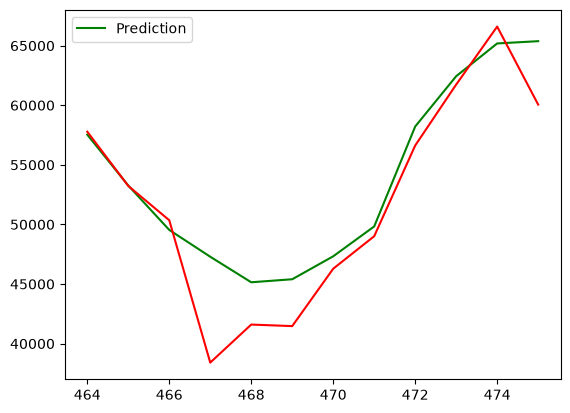

In [54]:
prediction.plot(color='g')
y_test.plot(color='r')
plt.show()

# or
# y_test.plot(color='r')
# prediction['Prediction'].plot(color='g')   # y_test is series and prediciton is df so plot 2 graph so we used prediction's column as series 
# plt.show()

# BoxCoxEndogTransformer

In [55]:
from pmdarima.pipeline import Pipeline
from pmdarima.preprocessing import BoxCoxEndogTransformer
import pmdarima as pm

In [56]:
pipe = Pipeline([
    ('boxcox',BoxCoxEndogTransformer()),
    ('model',pm.AutoARIMA(seasonal=True, suppress_warnings=True, m=12))
])
pipe.fit(y_train)

,steps,"[('boxcox', ...), ('model', ...)]"
Name,Type,Value
n_samples_,int,464
steps_,list,"[('boxcox', BoxCoxEndogTransformer()), ('model', AutoARIMA(m=12))]"
x_feats_,NoneType,None


In [57]:
forecast = pipe.predict(n_periods=len(y_test))
prediction = pd.DataFrame(forecast, index=y_test.index, columns=['Prediction'])
prediction

,Prediction
464,56895.839623
465,53528.965530
466,50129.439885
467,46776.104972
468,44394.605406
469,45281.290549
470,48863.125286
471,50255.688519
472,59134.515183
473,63433.402896


In [58]:
print('Total RMSE %.3f' %root_mean_squared_error(y_test,prediction))

Total RMSE 3593.527


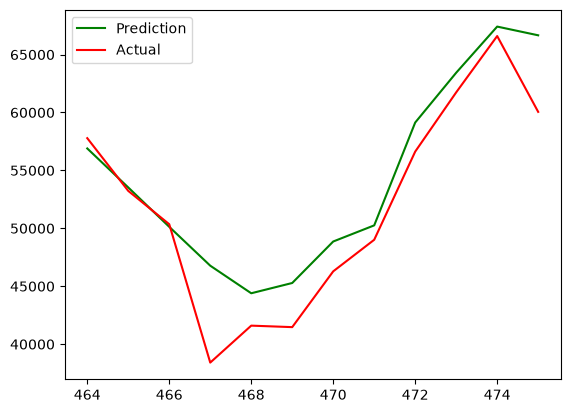

In [59]:
prediction.plot(color='g',label='Prediction')
y_test.plot(color='r',label='Actual')
plt.legend()
plt.show()